# SIHEDAF v2 — Evaluasi Robust (Langkah 1)

**Tujuan.** Memastikan selisih performa antar model itu *nyata* atau hanya noise, sebelum mencoba perbaikan (ensemble, smoothing antar-window) atau model baru (input EKG mentah).

Masalah protokol di `../v2_revisi/revisi_sihedaf_v2.ipynb` dan perbaikannya di sini:

| # | Masalah | Di notebook ini |
|---|---|---|
| 1 | Hanya satu partisi pasien. Std Macro-F1 per fold (±0.10–0.12) lebih besar dari selisih antar model | 5 ulangan × 5 fold, pasien diacak ulang tiap ulangan |
| 2 | `StratifiedGroupKFold(shuffle=True)` dengan 23 pasien hampir deterministik: pasien AFL selalu jatuh di fold yang sama untuk seed berapa pun | Pasien diacak di dalam strata (AFL / dominan AFIB / lainnya) lalu dibagikan round-robin (`sihedaf_cv.repeated_patient_folds`) |
| 3 | Tidak ada interval kepercayaan | Bootstrap level pasien (stratified, 2.000×) → CI 95% |
| 4 | Antar model tidak dibandingkan berpasangan | Selisih berpasangan (sampel bootstrap yang sama) terhadap model produksi + P(Δ > 0) |
| 5 | Tabel utama di data `annotation`, padahal produksi memakai detektor 50 Hz | Sumber utama `detector` (= kondisi produksi) |

**Prasyarat:** `../v2_revisi/revisi_sihedaf_v2.ipynb` sudah dijalankan (butuh `../cache/dataset_v2_detector.npz`). Notebook ini **tidak** melatih ulang model produksi dan tidak menyentuh `../v2_revisi/model_export/`.

OOF tiap (model, ulangan) di-cache di `../cache/oof_robust/<tag>/`. Run yang terputus bisa dilanjutkan, dan langkah 2 (ensemble/smoothing) memakai OOF yang sama.

> Uji alur cepat: set `SIHEDAF_QUICK=1` (2 epoch, 2 ulangan). Hasilnya disimpan di folder cache terpisah.

## 0. Setup

In [1]:
import os, time, importlib
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import sihedaf_cv as cv
importlib.reload(cv)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
QUICK = os.environ.get("SIHEDAF_QUICK") == "1"


@dataclass
class EvalConfig:
    source: str = "detector"           # "detector" = kondisi produksi 50 Hz; "annotation" = sebanding tabel lama
    cache_dir: str = "../cache"
    n_splits: int = 5
    n_repeats: int = 5
    seed: int = 2026                   # beda dari seed 42 notebook revisi → partisi baru
    n_boot: int = 2000
    # hiperparameter DL = notebook revisi
    epochs: int = 30
    batch_size: int = 256
    lr: float = 1e-3
    weight_decay: float = 1e-4
    dl_models: tuple = ("MicroTransformer", "MaskedResNet1D", "BiGRUAttention")
    # Model sekecil ini dibatasi overhead Python per batch, bukan GPU. Satu proses GPU
    # untuk MicroTransformer & ResNet; BiGRU (paling lambat di GPU, relatif cepat di CPU)
    # jalan bersamaan di worker CPU.
    cpu_models: tuple = ("BiGRUAttention",)
    cpu_workers: int = 2
    cpu_threads: int = 2
    reference: str = "MicroTransformer +bias"   # model produksi saat ini (model_export/sihedaf_v2)


ecfg = EvalConfig()
if QUICK:
    ecfg.epochs, ecfg.n_repeats, ecfg.n_boot = 2, 2, 200

MODEL_KWARGS = {
    "MicroTransformer": dict(input_dim=2, d_model=32, nhead=2, dim_ff=64, num_classes=3, dropout=0.1),
    "MaskedResNet1D":   dict(input_dim=2, num_classes=3),
    "BiGRUAttention":   dict(input_dim=2, hidden=32, num_classes=3),
}
HAS_CUDA = torch.cuda.is_available()
TAG = f"{ecfg.source}_e{ecfg.epochs}_r{ecfg.n_repeats}_s{ecfg.seed}"
OOF_DIR = Path(ecfg.cache_dir) / "oof_robust" / TAG
OOF_DIR.mkdir(parents=True, exist_ok=True)


def oof_path(name, r):
    return OOF_DIR / f"{name}_r{r}.npz"


print(f"CUDA={HAS_CUDA} | QUICK={QUICK} | OOF → {OOF_DIR}")
print(asdict(ecfg))

CUDA=True | QUICK=False | OOF → ../cache/oof_robust/detector_e30_r5_s2026
{'source': 'detector', 'cache_dir': '../cache', 'n_splits': 5, 'n_repeats': 5, 'seed': 2026, 'n_boot': 2000, 'epochs': 30, 'batch_size': 256, 'lr': 0.001, 'weight_decay': 0.0001, 'dl_models': ('MicroTransformer', 'MaskedResNet1D', 'BiGRUAttention'), 'cpu_models': ('BiGRUAttention',), 'cpu_workers': 2, 'cpu_threads': 2, 'reference': 'MicroTransformer +bias'}


## 1. Data & partisi pasien berulang

Tabel di bawah: pasien AFL yang ada di fold uji, per ulangan. Dengan partisi lama, kolom-kolom ini identik untuk seed berapa pun.

In [2]:
DATA_PATH = Path(ecfg.cache_dir) / f"dataset_v2_{ecfg.source}.npz"
assert DATA_PATH.exists(), f"{DATA_PATH} belum ada. Jalankan ../v2_revisi/revisi_sihedaf_v2.ipynb dulu."
z = np.load(DATA_PATH)
D = {k: z[k] for k in z.files}
y, records = D["y"], D["records"].astype(str)
PATIENTS = np.unique(records)
STRATA = cv.patient_strata(y, records, PATIENTS)
print(f"{len(y):,} window | {len(PATIENTS)} pasien | jumlah per kelas {np.bincount(y, minlength=3).tolist()}")
print(f"Pasien AFL ({(STRATA == 2).sum()}): {PATIENTS[STRATA == 2].tolist()}")
print(f"Pasien dominan AFIB ({(STRATA == 1).sum()}), lainnya ({(STRATA == 0).sum()})")

FOLDS_PATH = OOF_DIR / "folds.npz"
if FOLDS_PATH.exists():
    FOLDS = np.load(FOLDS_PATH)["folds"]
    assert FOLDS.shape == (ecfg.n_repeats, len(y)), f"{FOLDS_PATH} tidak cocok dengan dataset. Hapus folder {OOF_DIR}."
else:
    FOLDS = cv.repeated_patient_folds(y, records, ecfg.n_splits, ecfg.n_repeats, ecfg.seed)
    np.savez(FOLDS_PATH, folds=FOLDS)

audit = pd.DataFrame(
    [[", ".join(sorted(set(records[(FOLDS[r] == k) & (y == 2)]))) or "—" for k in range(ecfg.n_splits)]
     for r in range(ecfg.n_repeats)],
    index=[f"ulangan {r}" for r in range(ecfg.n_repeats)],
    columns=[f"fold {k}" for k in range(ecfg.n_splits)])
audit.index.name = "pasien AFL di fold uji"
display(audit)

165,978 window | 23 pasien | jumlah per kelas [99000, 65826, 1152]
Pasien AFL (7): ['04043', '04908', '04936', '06426', '07910', '08215', '08378']
Pasien dominan AFIB (7), lainnya (9)


,fold 0,fold 1,fold 2,fold 3,fold 4
pasien AFL di fold uji,,,,,
ulangan 0,08215,04908,08378,"04043, 07910","04936, 06426"
ulangan 1,"06426, 08215","04043, 08378",07910,04936,04908
ulangan 2,08215,06426,"04936, 08378","04908, 07910",04043
ulangan 3,08378,06426,04908,"07910, 08215","04043, 04936"
ulangan 4,04908,04936,07910,"08215, 08378","04043, 06426"


## 2. OOF LightGBM (16 fitur HRV, `class_weight="balanced"`)

In [3]:
for r in range(ecfg.n_repeats):
    p = oof_path("LightGBM", r)
    if p.exists():
        continue

    def fit_predict(tr, te, seed):
        return cv.make_lgbm(seed).fit(D["F"][tr], y[tr]).predict_proba(D["F"][te])

    oof, times = cv.cv_oof(fit_predict, D, FOLDS[r], seed=ecfg.seed + 100 * r)
    np.savez(p, oof=oof, times=np.asarray(times))
    print(f"LightGBM ulangan {r}: {np.mean(times):.1f}s/fold")
print("✓ OOF LightGBM lengkap")

✓ OOF LightGBM lengkap


## 3. OOF deep learning (paralel, bisa dilanjutkan)

Hiperparameter dan loss sama dengan notebook revisi (weighted CE, AdamW, cosine, 30 epoch, batch 256). Seed latih fold *k* di ulangan *r* = `seed + 100·r + k`. Job yang OOF-nya sudah ada dilewati.

In [4]:
def make_job(name, r):
    on_cpu = name in ecfg.cpu_models or not HAS_CUDA
    return {
        "model": name, "model_kwargs": MODEL_KWARGS[name], "repeat": r,
        "seed": ecfg.seed + 100 * r, "device": "cpu" if on_cpu else "cuda",
        "threads": ecfg.cpu_threads if on_cpu else 2,
        "data_path": str(DATA_PATH), "folds_path": str(FOLDS_PATH), "out": str(oof_path(name, r)),
        "hparams": dict(epochs=ecfg.epochs, batch_size=ecfg.batch_size, lr=ecfg.lr,
                        weight_decay=ecfg.weight_decay),
    }


jobs = [make_job(m, r) for r in range(ecfg.n_repeats) for m in ecfg.dl_models if not oof_path(m, r).exists()]
gpu_jobs = [j for j in jobs if j["device"] == "cuda"]
cpu_jobs = [j for j in jobs if j["device"] == "cpu"]
print(f"{len(jobs)} job tersisa: {len(gpu_jobs)} GPU, {len(cpu_jobs)} CPU")

if jobs:
    ctx = mp.get_context("spawn")
    t0 = time.perf_counter()
    with ProcessPoolExecutor(1, mp_context=ctx) as gpu_ex, \
         ProcessPoolExecutor(max(1, ecfg.cpu_workers), mp_context=ctx) as cpu_ex:
        futs = {gpu_ex.submit(cv.run_dl_job, j): j for j in gpu_jobs}
        futs.update({cpu_ex.submit(cv.run_dl_job, j): j for j in cpu_jobs})
        for f in as_completed(futs):
            j = futs[f]
            _, t = f.result()
            print(f"  [{(time.perf_counter() - t0) / 60:5.1f} mnt] {j['model']:<17} ulangan {j['repeat']} "
                  f"({j['device']}) {t:.0f}s/fold", flush=True)
print("✓ OOF deep learning lengkap")

0 job tersisa: 0 GPU, 0 CPU
✓ OOF deep learning lengkap


## 4. Prediksi: argmax & bias kelas cross-fit

Varian `+bias` = bias log-prob per kelas yang dipelajari dari OOF fold lain (sama seperti model produksi). Rentang bias antar fold memperlihatkan seberapa stabil kalibrasinya.

Grid bias diperlebar dari `-3…+3` (notebook revisi) ke `-7…+3`. Bias AFL model produksi (`[0, 2, -3]`) tepat di batas bawah grid lama, tanda nilai optimalnya terpotong.

In [5]:
MODELS = ["LightGBM", *ecfg.dl_models]
OOF = {m: np.stack([np.load(oof_path(m, r))["oof"] for r in range(ecfg.n_repeats)]) for m in MODELS}
FOLD_TIME = {m: float(np.mean([np.load(oof_path(m, r))["times"].mean() for r in range(ecfg.n_repeats)]))
             for m in MODELS}

CMS, BIAS = {}, {}
for m in MODELS:
    for variant in ("argmax", "+bias"):
        key = f"{m} {variant}"
        preds, biases = [], []
        for r in range(ecfg.n_repeats):
            prob = OOF[m][r]
            if variant == "+bias":
                prob, b = cv.crossfit_bias(y, prob, FOLDS[r])
                biases.append(b)
            preds.append(prob.argmax(1))
        CMS[key] = np.stack([cv.patient_cms(y, p, records, PATIENTS) for p in preds])   # (R, P, 3, 3)
        if biases:
            BIAS[key] = np.concatenate(biases)

g_lo, g_hi = cv.BIAS_GRID.min(), cv.BIAS_GRID.max()
print(f"Grid bias {g_lo:+.0f}…{g_hi:+.0f} (notebook revisi: -3…+3)")
for k, b in BIAS.items():
    at_edge = np.mean((b[:, 1:] <= g_lo) | (b[:, 1:] >= g_hi))
    print(f"{k:<24} bias AFIB {b[:, 1].mean():+.2f} ({b[:, 1].min():+.2f}…{b[:, 1].max():+.2f}) | "
          f"bias AFL {b[:, 2].mean():+.2f} ({b[:, 2].min():+.2f}…{b[:, 2].max():+.2f})"
          + (f" | ⚠ {at_edge:.0%} di batas grid" if at_edge else ""))

Grid bias -7…+3 (notebook revisi: -3…+3)
LightGBM +bias           bias AFIB -0.59 (-1.50…+1.50) | bias AFL -1.51 (-6.00…+0.50)
MicroTransformer +bias   bias AFIB -0.55 (-1.00…+0.25) | bias AFL -4.56 (-5.50…-4.00)
MaskedResNet1D +bias     bias AFIB -1.29 (-2.25…-0.25) | bias AFL -5.09 (-7.00…-2.75) | ⚠ 2% di batas grid
BiGRUAttention +bias     bias AFIB -0.38 (-1.00…+0.75) | bias AFL -4.46 (-5.75…-3.25)


### 4b. Efek grid bias lama

Model produksi dikalibrasi dengan grid `-3…+3`. Tabel ini membandingkan varian `+bias` dengan grid lama vs grid baru pada fold dan OOF yang sama, jadi selisihnya murni dari grid.

In [6]:
OLD_GRID = np.linspace(-3, 3, 25)
grid_rows = []
for m in MODELS:
    cms_old = []
    for r in range(ecfg.n_repeats):
        prob, f_r = OOF[m][r], FOLDS[r]
        adj = np.empty_like(prob)
        for k in np.unique(f_r):
            b = cv.fit_class_bias(y[f_r != k], prob[f_r != k], grid=OLD_GRID)
            adj[f_r == k] = cv.apply_bias(prob[f_r == k], b)
        cms_old.append(cv.patient_cms(y, adj.argmax(1), records, PATIENTS))
    old, new = cv.point_metrics(np.stack(cms_old)), cv.point_metrics(CMS[f"{m} +bias"])
    row = {"Model": m}
    for met in ("Macro-F1", "AFL F1", "AFL P"):
        row[f"{met} grid lama"] = round(float(old[met].mean()), 3)
        row[f"{met} grid baru"] = round(float(new[met].mean()), 3)
    grid_rows.append(row)
GRID_CMP = pd.DataFrame(grid_rows).set_index("Model")
display(GRID_CMP)

,Macro-F1 grid lama,Macro-F1 grid baru,AFL F1 grid lama,AFL F1 grid baru,AFL P grid lama,AFL P grid baru
Model,,,,,,
LightGBM,0.750,0.742,0.419,0.397,0.431,0.421
MicroTransformer,0.816,0.832,0.603,0.647,0.580,0.715
MaskedResNet1D,0.790,0.781,0.501,0.482,0.436,0.473
BiGRUAttention,0.822,0.829,0.601,0.621,0.614,0.692


## 5. Hasil utama dengan CI 95%

**Cara membaca.** Angka = rata-rata metrik pooled OOF dari semua ulangan. `[a–b]` = CI 95% bootstrap level pasien (pasien diresampel per strata, jadi tiap sampel tetap berisi pasien AFL). `± ulangan` = std antar ulangan (variasi karena partisi + seed). CI yang lebar berarti pasiennya sedikit, belum tentu modelnya jelek.

In [7]:
W = cv.bootstrap_weights(STRATA, ecfg.n_boot, seed=ecfg.seed)
BOOT = {k: cv.boot_metrics(c, W) for k, c in CMS.items()}
POINT = {k: cv.point_metrics(c) for k, c in CMS.items()}
SHOW = ["Macro-F1", "AFL F1", "AFL P", "AFL R", "AFIB F1", "Normal R"]


def ci(k, met):
    return np.percentile(BOOT[k][met], [2.5, 97.5])


rows = []
for k in CMS:
    m = k.rsplit(" ", 1)[0]
    row = {"Model": k}
    for met in SHOW:
        lo, hi = ci(k, met)
        row[met] = f"{POINT[k][met].mean():.3f} [{lo:.2f}–{hi:.2f}]"
    row["Macro-F1 ± ulangan"] = round(float(POINT[k]["Macro-F1"].std()), 3)
    row["Latih/fold (s)"] = round(FOLD_TIME[m], 1)
    row["Perangkat"] = "cpu" if (m == "LightGBM" or m in ecfg.cpu_models or not HAS_CUDA) else "cuda"
    rows.append(row)
RES = pd.DataFrame(rows).set_index("Model")
RES.to_csv(OOF_DIR / "ringkasan.csv")
display(RES)

,Macro-F1,AFL F1,AFL P,AFL R,AFIB F1,Normal R,Macro-F1 ± ulangan,Latih/fold (s),Perangkat
Model,,,,,,,,,
LightGBM argmax,0.770 [0.64–0.81],0.468 [0.08–0.58],0.449 [0.05–0.65],0.493 [0.13–0.60],0.907 [0.87–0.94],0.919 [0.84–0.96],0.011,3.4,cpu
LightGBM +bias,0.742 [0.63–0.79],0.397 [0.05–0.55],0.421 [0.05–0.64],0.376 [0.06–0.57],0.896 [0.85–0.93],0.928 [0.85–0.97],0.023,3.4,cpu
MicroTransformer argmax,0.717 [0.62–0.78],0.313 [0.04–0.48],0.201 [0.02–0.35],0.711 [0.31–0.98],0.907 [0.86–0.94],0.895 [0.81–0.94],0.010,88.2,cuda
MicroTransformer +bias,0.832 [0.67–0.92],0.647 [0.17–0.89],0.715 [0.26–0.95],0.592 [0.13–0.91],0.909 [0.86–0.94],0.924 [0.84–0.97],0.020,88.2,cuda
MaskedResNet1D argmax,0.728 [0.63–0.85],0.324 [0.04–0.67],0.218 [0.02–0.59],0.678 [0.27–0.97],0.924 [0.89–0.95],0.906 [0.84–0.96],0.031,110.5,cuda
MaskedResNet1D +bias,0.781 [0.65–0.88],0.482 [0.08–0.77],0.473 [0.07–0.93],0.521 [0.12–0.77],0.918 [0.89–0.94],0.944 [0.90–0.98],0.045,110.5,cuda
BiGRUAttention argmax,0.717 [0.63–0.78],0.293 [0.04–0.46],0.185 [0.02–0.34],0.704 [0.31–0.98],0.918 [0.88–0.95],0.909 [0.84–0.95],0.010,429.2,cpu
BiGRUAttention +bias,0.829 [0.68–0.92],0.621 [0.17–0.90],0.692 [0.19–0.95],0.564 [0.15–0.92],0.921 [0.89–0.95],0.934 [0.87–0.97],0.014,429.2,cpu


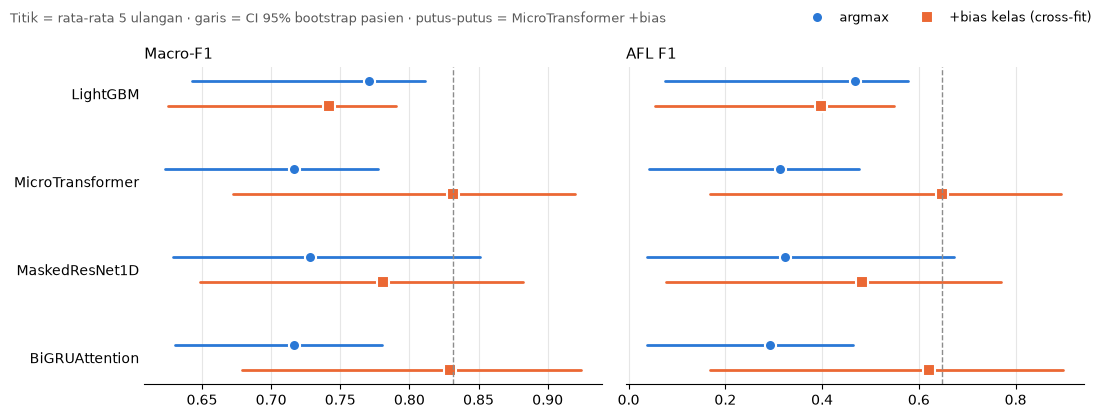

In [8]:
COLOR = {"argmax": "#2a78d6", "+bias": "#eb6834"}
MARKER = {"argmax": "o", "+bias": "s"}
LABEL = {"argmax": "argmax", "+bias": "+bias kelas (cross-fit)"}

fig, axes = plt.subplots(1, 2, figsize=(11, 0.65 * len(MODELS) + 1.6), sharey=True)
for ax, met in zip(axes, ["Macro-F1", "AFL F1"]):
    for i, m in enumerate(MODELS):
        for dy, v in ((-0.14, "argmax"), (0.14, "+bias")):
            k = f"{m} {v}"
            lo, hi = ci(k, met)
            ax.plot([lo, hi], [i + dy] * 2, color=COLOR[v], lw=2, solid_capstyle="round")
            ax.plot(POINT[k][met].mean(), i + dy, MARKER[v], color=COLOR[v], ms=8, mec="white", mew=1.5,
                    label=LABEL[v] if (i == 0 and ax is axes[0]) else None)
    ax.axvline(POINT[ecfg.reference][met].mean(), color="0.55", lw=1, ls="--")
    ax.set_title(met, loc="left", fontsize=11)
    ax.grid(axis="x", color="0.9", lw=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0)
axes[0].set_yticks(range(len(MODELS)), MODELS)
axes[0].invert_yaxis()
fig.legend(loc="upper right", ncol=2, frameon=False, fontsize=9)
fig.suptitle(f"Titik = rata-rata {ecfg.n_repeats} ulangan · garis = CI 95% bootstrap pasien · "
             f"putus-putus = {ecfg.reference}", x=0.01, ha="left", fontsize=9, color="0.35")
plt.tight_layout()
plt.show()

## 6. Perbandingan berpasangan terhadap model produksi

Δ = metrik(model) − metrik(referensi), dihitung pada sampel bootstrap pasien yang **sama**, sehingga variasi antar pasien saling meniadakan. P(Δ > 0) ≥ 0.95 → **lebih baik** secara konsisten; ≤ 0.05 → **lebih buruk**; di antaranya → **tidak terbedakan** dengan data ini.

In [9]:
def verdict(p):
    return "lebih baik" if p >= 0.95 else "lebih buruk" if p <= 0.05 else "tidak terbedakan"


cmp_rows = []
for k in CMS:
    if k == ecfg.reference:
        continue
    row = {"Model": k}
    for met in ("Macro-F1", "AFL F1"):
        d = BOOT[k][met] - BOOT[ecfg.reference][met]
        lo, hi = np.percentile(d, [2.5, 97.5])
        p = float(np.mean(d > 0))
        row[f"Δ {met}"] = f"{POINT[k][met].mean() - POINT[ecfg.reference][met].mean():+.3f} [{lo:+.2f}…{hi:+.2f}]"
        row[f"P(Δ {met}>0)"] = round(p, 2)
        row[f"vonis {met}"] = verdict(p)
    cmp_rows.append(row)
CMP = pd.DataFrame(cmp_rows).set_index("Model")
CMP.to_csv(OOF_DIR / "banding_vs_referensi.csv")
print(f"Referensi: {ecfg.reference}")
display(CMP)

Referensi: MicroTransformer +bias


,Δ Macro-F1,P(Δ Macro-F1>0),vonis Macro-F1,Δ AFL F1,P(Δ AFL F1>0),vonis AFL F1
Model,,,,,,
LightGBM argmax,-0.061 [-0.16…-0.00],0.02,lebih buruk,-0.179 [-0.48…-0.00],0.03,lebih buruk
LightGBM +bias,-0.090 [-0.25…-0.01],0.00,lebih buruk,-0.250 [-0.73…-0.01],0.01,lebih buruk
MicroTransformer argmax,-0.115 [-0.20…-0.04],0.00,lebih buruk,-0.334 [-0.60…-0.11],0.01,lebih buruk
MaskedResNet1D argmax,-0.104 [-0.20…+0.00],0.03,lebih buruk,-0.323 [-0.59…-0.02],0.01,lebih buruk
MaskedResNet1D +bias,-0.051 [-0.12…-0.00],0.02,lebih buruk,-0.165 [-0.36…-0.03],0.01,lebih buruk
BiGRUAttention argmax,-0.115 [-0.20…-0.03],0.01,lebih buruk,-0.354 [-0.62…-0.11],0.01,lebih buruk
BiGRUAttention +bias,-0.002 [-0.01…+0.01],0.39,tidak terbedakan,-0.027 [-0.05…+0.02],0.11,tidak terbedakan


## 7. Per pasien: recall AFL & sumber AFL palsu (varian `+bias`)

Recall AFL ditulis `rata-rata (min–maks antar ulangan)`. Tabel kedua menghitung window non-AFL yang diprediksi AFL (rata-rata per ulangan). Kalau AFL palsu menumpuk di sedikit pasien, penyebabnya kemungkinan pola ritme khusus pasien itu, bukan model secara umum.

In [10]:
afl_pat = PATIENTS[STRATA == 2]
pi = np.searchsorted(PATIENTS, afl_pat)
tbl = {}
for k in CMS:
    if not k.endswith("+bias"):
        continue
    c = CMS[k][:, pi]                                   # (R, P_afl, 3, 3)
    rec = c[:, :, 2, 2] / c[:, :, 2, :].sum(-1)         # (R, P_afl)
    tbl[k.removesuffix(" +bias")] = [f"{rec[:, j].mean():.2f} ({rec[:, j].min():.2f}–{rec[:, j].max():.2f})"
                                     for j in range(len(pi))]
AFL_PAT = pd.DataFrame(tbl, index=afl_pat)
AFL_PAT["window AFL"] = [int(((records == p) & (y == 2)).sum()) for p in afl_pat]
AFL_PAT.index.name = "recall AFL per pasien"
display(AFL_PAT)

fp = {k.removesuffix(" +bias"): CMS[k][:, :, :2, 2].sum(-1).mean(0) for k in CMS if k.endswith("+bias")}
FP = pd.DataFrame(fp, index=PATIENTS)
FP["window non-AFL"] = [int(((records == p) & (y != 2)).sum()) for p in PATIENTS]
FP["punya AFL"] = np.where(STRATA == 2, "ya", "")
ref_m = ecfg.reference.removesuffix(" +bias")
FP = FP.sort_values(ref_m, ascending=False)
FP.index.name = "AFL palsu per pasien"
display(FP.head(10).round(0))
for m in fp:
    top3 = np.sort(fp[m])[::-1][:3].sum() / max(fp[m].sum(), 1)
    print(f"{m:<17} total AFL palsu {fp[m].sum():7.0f} window/ulangan | 3 pasien teratas = {top3:.0%}")

,LightGBM,MicroTransformer,MaskedResNet1D,BiGRUAttention,window AFL
recall AFL per pasien,,,,,
04043,0.20 (0.00–1.00),0.40 (0.00–1.00),1.00 (1.00–1.00),0.60 (0.00–1.00),1
04908,1.00 (1.00–1.00),0.92 (0.87–1.00),0.77 (0.57–0.85),0.87 (0.72–1.00),46
04936,0.53 (0.38–0.57),0.51 (0.37–0.57),0.46 (0.36–0.51),0.46 (0.38–0.53),673
06426,0.04 (0.00–0.14),0.17 (0.14–0.24),0.10 (0.00–0.19),0.28 (0.00–0.62),21
07910,0.04 (0.00–0.17),0.00 (0.00–0.00),0.03 (0.00–0.12),0.01 (0.00–0.05),96
08215,0.00 (0.00–0.00),0.00 (0.00–0.00),0.00 (0.00–0.00),0.00 (0.00–0.00),9
08378,0.09 (0.01–0.31),0.96 (0.79–1.00),0.82 (0.11–1.00),0.97 (0.84–1.00),306


,LightGBM,MicroTransformer,MaskedResNet1D,BiGRUAttention,window non-AFL,punya AFL
AFL palsu per pasien,,,,,,
04936,166.0,169.0,163.0,162.0,6582,ya
04043,199.0,69.0,618.0,92.0,7064,ya
07879,111.0,12.0,4.0,13.0,7318,
08378,5.0,6.0,2.0,6.0,7030,ya
04908,16.0,4.0,2.0,2.0,7293,ya
06995,19.0,3.0,2.0,4.0,7344,
08405,21.0,3.0,10.0,1.0,7332,
04746,13.0,2.0,1.0,2.0,7326,
08219,11.0,1.0,12.0,3.0,7153,


LightGBM          total AFL palsu     601 window/ulangan | 3 pasien teratas = 79%
MicroTransformer  total AFL palsu     274 window/ulangan | 3 pasien teratas = 91%
MaskedResNet1D    total AFL palsu     821 window/ulangan | 3 pasien teratas = 97%
BiGRUAttention    total AFL palsu     291 window/ulangan | 3 pasien teratas = 92%


## 8. Ringkasan otomatis

In [11]:
plus = [k for k in CMS if k.endswith("+bias")]
best = max(plus, key=lambda k: POINT[k]["Macro-F1"].mean())
lo_ref, hi_ref = ci(ecfg.reference, "AFL F1")
print(f"Macro-F1 tertinggi (varian +bias): {best} = {POINT[best]['Macro-F1'].mean():.3f}")
print(f"Lebar CI 95% AFL F1 referensi: {lo_ref:.2f}–{hi_ref:.2f} (selebar {hi_ref - lo_ref:.2f})")
for met in ("Macro-F1", "AFL F1"):
    col = f"vonis {met}"
    for v in ("lebih baik", "lebih buruk", "tidak terbedakan"):
        names = CMP.index[CMP[col] == v].tolist()
        if names:
            print(f"{met}: {v} dari referensi → {', '.join(names)}")

Macro-F1 tertinggi (varian +bias): MicroTransformer +bias = 0.832
Lebar CI 95% AFL F1 referensi: 0.17–0.89 (selebar 0.73)
Macro-F1: lebih buruk dari referensi → LightGBM argmax, LightGBM +bias, MicroTransformer argmax, MaskedResNet1D argmax, MaskedResNet1D +bias, BiGRUAttention argmax
Macro-F1: tidak terbedakan dari referensi → BiGRUAttention +bias
AFL F1: lebih buruk dari referensi → LightGBM argmax, LightGBM +bias, MicroTransformer argmax, MaskedResNet1D argmax, MaskedResNet1D +bias, BiGRUAttention argmax
AFL F1: tidak terbedakan dari referensi → BiGRUAttention +bias


## 9. Kesimpulan

Sumber data `detector` (kondisi produksi 50 Hz), 5 ulangan × 5 fold pasien, CI 95% bootstrap pasien.

**1. Model produksi (MicroTransformer +bias) sudah yang terbaik di antara kandidat RR-only.** Macro-F1 0.832 [0.67–0.92], AFL F1 0.647 [0.17–0.89]. Semua varian lain *lebih buruk secara konsisten* (P(Δ>0) ≤ 0.03), kecuali BiGRUAttention +bias yang *tidak terbedakan* (Δ Macro-F1 −0.002, P = 0.39). Mengganti arsitektur RR-only tidak memberi keuntungan.

**2. Ranking tabel lama tidak bertahan.** MaskedResNet1D, yang terbaik di tabel lama (satu partisi, data `annotation`), di sini lebih buruk dari referensi dan paling tidak stabil antar ulangan (± 0.045). Selisih di satu partisi saja tidak cukup untuk memilih model.

**3. Kalibrasi bias kelas adalah faktor terbesar, dan grid lamanya terpotong.**
- Bias menaikkan Macro-F1 MicroTransformer dari 0.717 ke 0.832, dan AFL precision dari 0.20 ke 0.72.
- Bias AFL optimal berada di −4.0…−5.5, semuanya di bawah batas grid lama (−3). Bias produksi `[0, 2, −3]` di `model_export/sihedaf_v2.json` tepat di batas itu.
- Dengan grid diperlebar: AFL F1 0.603 → 0.647, AFL P 0.580 → 0.715 (fold dan OOF sama, bobot model tidak berubah).

**4. Weighted CE terlalu kuat untuk AFL.** Tanpa bias, AFL recall sekitar 0.7 tapi precision sekitar 0.2. Koreksi sebesar −4.5 log-unit (sekitar 90×) menunjukkan bobot kelas AFL (sekitar 48×) membuat model sangat over-prediksi AFL. Kandidat langkah 2: bobot lebih lunak (akar) atau logit-adjusted loss.

**5. Batas sebenarnya ada di data AFL, bukan model.**
- Recall AFL untuk pasien 07910 (96 window) dan 08215 (9 window) ≈ 0 di semua model.
- 06426 rendah (0.04–0.28), 04936 sekitar 0.5. Hanya 08378 dan 04908 yang terdeteksi baik.
- CI AFL F1 selebar 0.73. Variasi antar ulangan kecil (± 0.01–0.02), jadi ketidakpastian didominasi *pasien mana yang ada di data*, bukan pembagian fold.

**6. AFL palsu hampir semuanya terjadi pada pasien yang memang punya AFL.** Untuk MicroTransformer, sekitar 87% AFL palsu berasal dari window non-AFL milik 04936 dan 04043. Pada pasien tanpa AFL, AFL palsu jarang (≤ 12 dari sekitar 7.000 window per pasien). Pola ini cocok dengan window transisi di sekitar episode AFL, sehingga smoothing antar-window (langkah 2) relevan.

**Langkah berikutnya:**
1. Kalibrasi ulang `class_bias` produksi dengan grid lebar. Cukup mengubah `sihedaf_v2.json`; bobot `.pt` tetap.
2. Langkah 2: smoothing antar-window, ensemble MicroTransformer + BiGRU, dan bobot kelas yang lebih lunak. Semuanya dievaluasi dengan protokol ini; OOF sudah tersedia di `../cache/oof_robust/`.
3. Untuk pasien AFL yang gagal di semua model (07910, 08215, 06426): cabang input EKG mentah atau data AFL tambahan.